# Secular vs exact q=1 Vendi: exact scores, tie-broken batches

The sweep `launchers/sweep_exp_cifar10_imb_vendi_secular.py` (2026-09-21/22, wandb project `vendi-approx`) ran
q=1 Vendi on CIFAR-10-imb (med) for every rbf setting — embedding {feat, grad} × normalization
{minmax, zscore, l2, none} × gamma {1, dim, median} — once with the C secular solver
(`query.vendi.secular=True`) and once with the production dense eigendecomposition. In 8 of the 23
finished pairs the two runs acquired different batches; both grad-rbfmed-minmax runs crashed (§3 shows why).
This notebook checks two claims:

1. **The secular solver computes exact Vendi scores.** Its spectra and scores are compared with an
   independent 30-digit (mpmath) eigendecomposition and with the dense solver, and its spectra are
   checked against identities every exact spectrum must satisfy (trace, Frobenius norm, Cauchy
   interlacing). This is done for all 24 settings, which span identity-like, all-ones-like and mixed
   kernels.
2. **The batches differ only through ties.** Every candidate that one run acquired and the other didn't
   has a score equal to the cutoff score to within float64 precision, and argsort breaks such ties
   arbitrarily. Where the cutoff isn't tied, both solvers acquire the same 250 samples.

**Where the scores come from.** q=1 runs don't store per-candidate scores (only acquired/unacquired
max/min/median in `extra_info_{i}.npz` and wandb), so round 0 is recomputed from each run's saved
`loop-0` checkpoint and labeled set. Round 0 is the clean comparison: both runs of a pair query the same
trained model and labeled set. From round 1 on, their batches (and so their models) differ.

**Runtime.** First run ~35 min: the dense solve takes ~1 min per setting on the GPU, plus ~170 mpmath
eigendecompositions of 251×251 matrices. Everything is cached in
`analysis/cache/vendi_secular_exactness/`; set `FORCE_RECOMPUTE = True` to redo it.

In [1]:
import ipynb_setup  # adds src/ to sys.path and loads .env
import contextlib
import hashlib
import json
import math
import multiprocessing
import os
import time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import mpmath
import numpy as np
import pandas as pd
import torch
from omegaconf import OmegaConf

import query.query_diversity as qd  # also puts vendi-approx/src on sys.path
from utils.io import load_pickle
from vendi_c import secular_scores  # the C solver the production secular wrapper calls
from vendi_from_features_secular import vendi_from_features_secular

ROOT = Path("..").resolve()
RUN_BASE = ROOT / "experiments/activelearning/cifar10_imb/active-cifar10_med"
CACHE = ROOT / "analysis/cache/vendi_secular_exactness"
CACHE.mkdir(parents=True, exist_ok=True)
FORCE_RECOMPUTE = False  # True: ignore cached embeddings/scores and recompute everything
SETTINGS = None          # None = all 24; a subset must include feat-rbf1-zscore, feat-rbfmed-l2, grad-rbf1-none

B = 250            # acquisition size (active=cifar10_med)
REL_TOL = 1e-12    # scores: "equal to 12 significant digits" (solver accuracy bar and tie resolution)
EIG_TOL = 2.0      # eigenvalues: errors accepted up to EIG_TOL x tau, the secular solver's deflation tolerance
EPS = np.finfo(float).eps
N_REF_RANDOM = 4   # random pool candidates per setting checked against the 30-digit reference
MP_DPS = 30        # digits for the mpmath reference eigendecomposition
MP_WORKERS = 8
DEVICE = qd.DEVICE
print("device:", DEVICE)

Loading .env from /home/jing/Desktop/realistic-al/.env


/home/jing/anaconda3/envs/real-al/lib/python3.10/site-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)


device: cuda:0


/home/jing/anaconda3/envs/real-al/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Two precision bars:

- **Scores, `REL_TOL = 1e-12`.** A solver passes if its Vendi scores are right to 12 significant digits,
  and two scores closer than that count as tied. For scale, the smallest cutoff gap in any setting whose
  batches matched is 2e-9 relative (§6), three orders of magnitude above this bar; a broken root-finder
  is off by 1e-6 or more.
- **Eigenvalues, `EIG_TOL = 2` in units of τ.** Here τ = L·ε·max(|λ_max(K_LL)|, 1) is the deflation
  tolerance of the C solver (`secular_roots` in `vendi-approx/c/vendi.c`): poles closer than τ are
  merged and couplings smaller than τ are dropped. So the secular spectrum is only promised to be
  accurate to about τ. τ ranges from about 1e-14 for identity-like kernels to about 1e-11 for
  all-ones-like ones, where λ_max ≈ 251. An eigenvalue error above 2τ would mean the solver misses its
  own design accuracy.

## 1. The sweep's runs

Each finished run is identified by its `.hydra/config.yaml`. Crashed attempts have no `stored.npz`;
these include the `gamma=med` typo runs and both grad-rbfmed-minmax runs. That setting has no stored
batches, but it is still scored below, since the solver check doesn't need a run.

In [2]:
GAMMA_SHORT = {"1.0": "1", "dim": "dim", "median": "med"}
GRID = [(e, n, g) for e in ("feat", "grad") for n in ("minmax", "zscore", "l2", "none")
        for g in ("1.0", "dim", "median")]


def setting_name(emb, norm, gamma):
    return f"{emb}-rbf{GAMMA_SHORT[str(gamma)]}-{norm}"


rows = []
for cfgp in sorted(RUN_BASE.glob("*/*secular*/*/.hydra/config.yaml")):
    rd = cfgp.parent.parent
    if not (rd / "stored.npz").exists():
        continue  # crashed / killed attempt
    v = OmegaConf.load(cfgp).query.vendi
    emb = "grad" if v.get("use_grad", False) else "feat"
    rows.append(dict(setting=setting_name(emb, v.normalization, v.gamma), emb=emb,
                     secular=bool(v.secular), rd=rd, batch_size=int(v.batch_size)))
runs = pd.DataFrame(rows)
assert not runs.duplicated(["setting", "secular"]).any(), "more than one finished run for a setting"
BATCH_SIZE = int(runs.batch_size.unique().item())  # vendi.batch_size of the production dense path

pairs = pd.DataFrame([dict(setting=setting_name(e, n, g), emb=e, norm=n, gamma=g) for e, n, g in GRID])
if SETTINGS:
    pairs = pairs[pairs.setting.isin(SETTINGS)].reset_index(drop=True)
for sec, col in ((False, "rd_exact"), (True, "rd_secular")):
    pairs = pairs.merge(runs.loc[runs.secular == sec, ["setting", "rd"]].rename(columns={"rd": col}),
                        on="setting", how="left")
print(f"{len(runs)} finished runs, dense batch_size={BATCH_SIZE}")
pairs.assign(exact_run=pairs.rd_exact.notna(), secular_run=pairs.rd_secular.notna())[
    ["setting", "exact_run", "secular_run"]].set_index("setting").T

46 finished runs, dense batch_size=64


setting,feat-rbf1-minmax,feat-rbfdim-minmax,feat-rbfmed-minmax,feat-rbf1-zscore,feat-rbfdim-zscore,feat-rbfmed-zscore,feat-rbf1-l2,feat-rbfdim-l2,feat-rbfmed-l2,feat-rbf1-none,...,grad-rbfmed-minmax,grad-rbf1-zscore,grad-rbfdim-zscore,grad-rbfmed-zscore,grad-rbf1-l2,grad-rbfdim-l2,grad-rbfmed-l2,grad-rbf1-none,grad-rbfdim-none,grad-rbfmed-none
exact_run,True,True,True,True,True,True,True,True,True,True,...,False,True,True,True,True,True,True,True,True,True
secular_run,True,True,True,True,True,True,True,True,True,True,...,False,True,True,True,True,True,True,True,True,True


## 2. Rebuild the round-0 inputs

A run's round-0 query sees the `loop-0` model and labeled set, neither of which depends on the Vendi
settings. Hashing both confirms that all runs of an embedding type queried identical inputs, so the
embeddings are rebuilt once per distinct input and shared. Rebuilding replicates `main.py`: seed first
(the imbalanced subsample uses `np.random`), then restore the labeled set. `init_state()` is needed
because `ActiveLearningDataset.load_state_dict` doesn't refresh the labeled index.

In [3]:
def round0_key(rd, emb):
    # Hash of the loop-0 model weights + labeled mask: equal keys => identical round-0 query inputs.
    (ckpt,) = (rd / "loop-0/checkpoints").glob("*.ckpt")
    sd = torch.load(ckpt, map_location="cpu", weights_only=False)["state_dict"]
    h = hashlib.sha1(emb.encode())
    for k in sorted(sd):
        h.update(k.encode())
        h.update(sd[k].numpy().tobytes())
    h.update(np.asarray(load_pickle(rd / "loop-0/data_ckpt.pkl")["labelled"]).tobytes())
    return h.hexdigest()[:12]


def rebuild_round0_embeddings(rd):
    # Round-0 query inputs of run `rd`, embedded with the production helper (features or gradients).
    import utils
    from models.bayesian import BayesianModule
    from run_training import get_torchvision_dm

    cfg = OmegaConf.load(rd / ".hydra/config.yaml")
    utils.set_seed(cfg.trainer.seed)
    dm = get_torchvision_dm(cfg)
    dm.train_set.load_checkpoint(str(rd / "loop-0/data_ckpt.pkl"))
    dm.train_set.init_state()
    model = BayesianModule(cfg)
    (ckpt,) = (rd / "loop-0/checkpoints").glob("*.ckpt")
    model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=False)["state_dict"])
    model = model.to(DEVICE).eval()
    eL, eU, _ = qd.get_vendi_embeddings(
        cfg.query.vendi, model,
        dm.labeled_dataloader(batch_size=dm.batch_size),
        dm.pool_dataloader(batch_size=dm.batch_size, m=None),
    )
    return eL.cpu(), eU.cpu()


runs["round0_key"] = [round0_key(r.rd, r.emb) for r in runs.itertuples()]
print(runs.groupby("emb").round0_key.unique())

EMB = {}
for key, g in runs.groupby("round0_key"):
    path = CACHE / f"emb_{key}.pt"
    if path.exists() and not FORCE_RECOMPUTE:
        EMB[key] = torch.load(path)
    else:
        EMB[key] = rebuild_round0_embeddings(g.rd.iloc[0])
        torch.save(EMB[key], path)
    print(f"{key} ({g.emb.iloc[0]}, {len(g)} runs): labeled {tuple(EMB[key][0].shape)}, pool {tuple(EMB[key][1].shape)}")

# each setting's input key: from its runs if it has any, else the one shared by its embedding type
key_of_emb = runs.groupby("emb").round0_key.agg(lambda s: s.unique().item() if s.nunique() == 1 else None)
pairs["key"] = [
    runs.loc[runs.setting == s, "round0_key"].unique().item() if (runs.setting == s).any() else key_of_emb[e]
    for s, e in zip(pairs.setting, pairs.emb)
]  # .item() fails if a pair's two runs saw different inputs

emb
feat    [dee054a2e48f]
grad    [46131bc59403]
Name: round0_key, dtype: object
46131bc59403 (grad, 22 runs): labeled (250, 5120), pool (12388, 5120)
dee054a2e48f (feat, 24 runs): labeled (250, 512), pool (12388, 512)


## 3. Score every setting with both solvers

Per setting, the kernels are built exactly as in `vendi_from_features`: float32 kernel on the GPU, cast
to float64. From them:

- **dense**: `dense_scores`, the production dense path (`vendi_from_features`, q=1, `approx=False`)
  written out so that it also returns each candidate's spectrum. §3a checks it is bitwise identical to
  the production function.
- **secular**: `vendi_c.secular_scores`, the call inside `vendi_from_features_secular` (also checked
  bitwise in §3a). It returns the spectra from the arrowhead secular equation and the scores computed
  from them by the C function `vendi_from_lam`.
- **secular spectra, production scoring**: the secular spectra scored by the same torch code the dense
  path uses. Comparing it with the C-scored version separates the secular *equation* from the scoring
  arithmetic.


In [4]:
def vendi_cfg(emb, norm, gamma):
    return OmegaConf.create(dict(
        q=1.0, kernel="rbf", gamma=gamma if gamma in ("dim", "median") else float(gamma),
        normalization=norm, batch_size=BATCH_SIZE, approx=False, use_grad=emb == "grad"))


def normalized(vcfg, key):
    eL, eU = EMB[key]
    return qd.normalize_features(eL.to(DEVICE), eU.to(DEVICE), vcfg.normalization)


def kernels(vcfg, eL, eU):
    # K_LL (L, L) and K_UL (U, L), float64 on DEVICE, built exactly like vendi_from_features.
    gamma = qd.resolve_gamma(vcfg.gamma, eL)
    K_LL = qd.compute_kernel_matrix(vcfg.kernel, gamma, eL, eL).to(torch.float64)
    K_UL = qd.compute_kernel_matrix(vcfg.kernel, gamma, eU, eL).to(torch.float64)
    return K_LL, K_UL, gamma


def production_scoring(spectra):
    # The scoring step of vendi_from_features (q=1) applied to spectra (N, L+1) -> scores (N,).
    ev = torch.as_tensor(spectra, device=DEVICE).clamp(min=0)
    ev = ev / ev.sum(dim=1, keepdim=True).clamp(min=1e-12)
    return qd.renyi_entropy(ev, 1.0).exp().cpu().numpy()


def dense_scores(K_LL, K_UL, batch_size=BATCH_SIZE):
    # Production dense q=1 scores (vendi_from_features, approx=False) + raw spectra (U, L+1), ascending.
    L, U = K_LL.shape[0], K_UL.shape[0]
    K = torch.empty(batch_size, L + 1, L + 1, device=DEVICE, dtype=torch.float64)
    K[:, :L, :L] = K_LL
    scores = torch.empty(U, device=DEVICE, dtype=torch.float64)
    spectra = torch.empty(U, L + 1, dtype=torch.float64)
    for i in range(math.ceil(U / batch_size)):
        sl = slice(batch_size * i, batch_size * (i + 1))
        kb = K_UL[sl]
        Kb = K[: kb.shape[0]]
        Kb[:, L, :L] = kb
        Kb[:, :L, L] = kb
        Kb[:, L, L] = 1.0  # k(u, u) = 1 for rbf
        ev = qd._robust_eigvalsh(Kb)
        spectra[sl] = ev.cpu()
        ev = ev.clamp(min=0)
        ev = ev / ev.sum(dim=1, keepdim=True).clamp(min=1e-12)
        scores[sl] = qd.renyi_entropy(ev, 1.0)
    return scores.exp().cpu().numpy(), spectra.numpy()


def boundary(scores):
    order = np.argsort(scores)[::-1]  # the ranking _get_vendi uses
    return int(order[B - 1]), int(order[B])  # last acquired, first excluded


def score_setting(row):
    path = CACHE / f"scores_{row.setting}.npz"
    if path.exists() and not FORCE_RECOMPUTE:
        return dict(np.load(path))
    vcfg = vendi_cfg(row.emb, row.norm, row.gamma)
    K_LL, K_UL, gamma = kernels(vcfg, *normalized(vcfg, row.key))
    if not (torch.isfinite(K_LL).all() and torch.isfinite(K_UL).all()):
        return None  # no Vendi score exists; see nonfinite_diagnosis
    diag = qd.kernel_diagnostics(vcfg.kernel, gamma, K_LL)
    E, E_spec = dense_scores(K_LL, K_UL)
    K_LL_np, K_UL_np = K_LL.cpu().numpy(), K_UL.cpu().numpy()
    S, S_spec = secular_scores(K_LL_np, K_UL_np, want_eigs=True)
    # Condition number of the score w.r.t. eigenvalue errors of size eps * lambda_max (what any
    # backward-stable eigensolver makes): |dVS / VS| ~= cond * eps. Near-zero eigenvalues p inflate it
    # through |log p|, so all-ones-like kernels have larger float64 error than identity-like ones.
    p = E_spec.clip(min=0)
    p = p / p.sum(1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        dlog = np.where(p > 0, np.abs(np.log(p) + 1.0), 0.0).sum(1)
    cond = dlog * np.abs(E_spec).max(1) / E_spec.clip(min=0).sum(1)
    # candidates for the 30-digit reference: both solvers' cutoff pairs + a few random ones
    rng = np.random.default_rng(0)
    ref = np.unique(np.r_[boundary(E), boundary(S), rng.choice(len(E), N_REF_RANDOM, replace=False)])
    out = dict(E=E, S=S, S_rescored=production_scoring(S_spec), cond=cond,
               eig_diff=np.abs(S_spec - E_spec).max(1),
               ref_idx=ref, ref_E_spec=E_spec[ref], ref_S_spec=S_spec[ref], K_LL=K_LL_np, ref_k=K_UL_np[ref],
               K_LL_asym=float((K_LL - K_LL.T).abs().max()), gamma=gamma, **diag)
    np.savez(path, **out)
    return out


def nonfinite_diagnosis(row):
    # Why a setting's kernel is not finite: the bandwidth and the float32 squared distances rbf_kernel uses.
    vcfg = vendi_cfg(row.emb, row.norm, row.gamma)
    eL, eU = normalized(vcfg, row.key)
    gamma = qd.resolve_gamma(vcfg.gamma, eL)
    out = dict(setting=row.setting, gamma=gamma)
    for name, (a, b) in (("LL", (eL, eL)), ("UL", (eU, eL))):
        d2 = (a ** 2).sum(1).view(-1, 1) + (b ** 2).sum(1).view(1, -1) - 2.0 * (a @ b.T)  # as in rbf_kernel
        K = qd.rbf_kernel(a, b, gamma)
        out.update({f"min_d2_{name}": d2.min().item(), f"n_negative_d2_{name}": int((d2 < 0).sum()),
                    f"n_inf_K_{name}": int(torch.isinf(K).sum()), f"n_nan_K_{name}": int(torch.isnan(K).sum())})
    return out


RES, NONFINITE = {}, []
for row in pairs.itertuples():
    t0 = time.time()
    res = score_setting(row)
    if res is None:
        NONFINITE.append(nonfinite_diagnosis(row))
        print(f"{row.setting:20s} kernel not finite - skipped")
        continue
    RES[row.setting] = res
    print(f"{row.setting:20s} {time.time() - t0:6.1f}s")
scored = pairs[pairs.setting.isin(RES)].reset_index(drop=True)  # settings with a finite kernel

feat-rbf1-minmax        0.0s
feat-rbfdim-minmax      0.0s
feat-rbfmed-minmax      0.0s
feat-rbf1-zscore        0.0s
feat-rbfdim-zscore      0.0s
feat-rbfmed-zscore      0.0s
feat-rbf1-l2            0.0s
feat-rbfdim-l2          0.0s
feat-rbfmed-l2          0.0s
feat-rbf1-none          0.0s
feat-rbfdim-none        0.0s
feat-rbfmed-none        0.0s
grad-rbf1-minmax        0.0s
grad-rbfdim-minmax      0.0s


grad-rbfmed-minmax   kernel not finite - skipped
grad-rbf1-zscore        0.0s
grad-rbfdim-zscore      0.0s
grad-rbfmed-zscore      0.0s
grad-rbf1-l2            0.0s
grad-rbfdim-l2          0.0s
grad-rbfmed-l2          0.0s
grad-rbf1-none          0.0s
grad-rbfdim-none        0.0s
grad-rbfmed-none        0.0s


### Settings without a finite kernel

A setting whose kernel contains inf or NaN has no Vendi score, so neither solver is run on it. The
table below shows the mechanism. When the median labeled pairwise distance is 0, `resolve_gamma`
returns γ = 1/1e-12 = 1e12. That happens with gradient embeddings under minmax, where many labeled
gradients collapse onto the same normalized vector. `rbf_kernel` then computes
d² = ‖x‖² + ‖y‖² − 2x·y in float32, which rounding can push below 0. It doesn't clamp at 0, so
exp(−γ·d²) overflows to inf. This is why both grad-rbfmed-minmax runs crashed in the sweep: the dense
run raised `LinAlgError` on an inf/nan kernel, and the secular run died at the start of round 0.

In [5]:
pd.DataFrame(NONFINITE).set_index("setting") if NONFINITE else 'every setting has a finite kernel'

,gamma,min_d2_LL,n_negative_d2_LL,n_inf_K_LL,n_nan_K_LL,min_d2_UL,n_negative_d2_UL,n_inf_K_UL,n_nan_K_UL
setting,,,,,,,,,
grad-rbfmed-minmax,1.000000e+12,-0.000977,14666,14666,0,-0.00293,608879,608879,0


### 3a. The helpers are the production code paths

`dense_scores` and `secular_scores` are compared with the production functions on one tied and one
clean setting, fed the same normalized features `_get_vendi` would pass. The scores must be equal bit
for bit.

In [6]:
BITWISE = {}
for name in ("feat-rbf1-zscore", "feat-rbfmed-l2"):
    row = pairs.set_index("setting").loc[name]
    vcfg = vendi_cfg(row["emb"], row["norm"], row["gamma"])
    eL, eU = normalized(vcfg, row["key"])
    with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), contextlib.redirect_stderr(dn):
        prod_dense, _ = qd.vendi_from_features(vcfg, eL, eU)            # production, secular=False
        prod_secular, _ = vendi_from_features_secular(vcfg, eL, eU)     # production, secular=True
    BITWISE[name] = (np.array_equal(prod_dense, RES[name]["E"]), np.array_equal(prod_secular, RES[name]["S"]))
    print(f"{name:18s} dense == production: {BITWISE[name][0]}   secular == production: {BITWISE[name][1]}")

feat-rbf1-zscore   dense == production: True   secular == production: True


feat-rbfmed-l2     dense == production: True   secular == production: True


### 3b. The kernels are the ones the runs saw

The runs logged kernel diagnostics of their round-0 labeled Gram matrix (`kernel_*` in
`extra_info_0.npz`). Recomputing them here must reproduce the logged values, which confirms the rebuilt
inputs match the runs'.

In [7]:
DIAG_KEYS = ["kernel_offdiag_mean", "kernel_offdiag_std", "kernel_frac_near_one",
             "kernel_frac_near_zero", "kernel_eff_rank_q2", "kernel_rbf_arg_median", "kernel_gamma"]


def logged_diag_err(row):
    errs = []
    for rd in (row.rd_exact, row.rd_secular):
        if isinstance(rd, Path):
            logged = np.load(rd / "extra_info_0.npz")
            errs += [abs(float(logged[k]) - float(RES[row.setting][k])) / max(abs(float(logged[k])), 1e-300)
                     for k in DIAG_KEYS]
    return max(errs) if errs else np.nan


scored["diag_rel_err"] = [logged_diag_err(r) for r in scored.itertuples()]
scored[["setting", "diag_rel_err"]].set_index("setting").T

setting,feat-rbf1-minmax,feat-rbfdim-minmax,feat-rbfmed-minmax,feat-rbf1-zscore,feat-rbfdim-zscore,feat-rbfmed-zscore,feat-rbf1-l2,feat-rbfdim-l2,feat-rbfmed-l2,feat-rbf1-none,...,grad-rbfdim-minmax,grad-rbf1-zscore,grad-rbfdim-zscore,grad-rbfmed-zscore,grad-rbf1-l2,grad-rbfdim-l2,grad-rbfmed-l2,grad-rbf1-none,grad-rbfdim-none,grad-rbfmed-none
diag_rel_err,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Against a 30-digit reference

For each setting's reference candidates (both solvers' last-acquired and first-excluded candidates,
plus random ones), the spectrum of the same float64 K_aug(u) is recomputed with a 30-digit mpmath
eigendecomposition. It involves no float64 arithmetic, so it shows how far each solver is from the
truth rather than just from the other solver.

In [8]:
def mp_spectrum(K_LL, k_u, dps=MP_DPS):
    # Eigenvalues (ascending) and Vendi score of K_aug = [[K_LL, k_u], [k_u^T, 1]] at `dps` digits, as strings.
    mpmath.mp.dps = dps
    L = K_LL.shape[0]
    A = np.empty((L + 1, L + 1))
    A[:L, :L] = K_LL
    A[L, :L] = A[:L, L] = k_u
    A[L, L] = 1.0
    lam = sorted(mpmath.eigsy(mpmath.matrix(A.tolist()), eigvals_only=True))
    pos = [max(x, 0) for x in lam]
    tot = mpmath.fsum(pos)
    H = -mpmath.fsum(p * mpmath.log(p) for p in (x / tot for x in pos) if p > 0)
    return [mpmath.nstr(x, dps) for x in lam], mpmath.nstr(mpmath.exp(H), dps)


mp_path = CACHE / f"mp_dps{MP_DPS}.json"
MP = json.loads(mp_path.read_text()) if mp_path.exists() and not FORCE_RECOMPUTE else {}
jobs = [(s, int(u)) for s in scored.setting for u in RES[s]["ref_idx"] if str(u) not in MP.get(s, {})]
if jobs:
    t0 = time.time()
    with ProcessPoolExecutor(MP_WORKERS, mp_context=multiprocessing.get_context("fork")) as ex:
        futs = {}
        for s, u in jobs:
            r = RES[s]
            futs[(s, u)] = ex.submit(mp_spectrum, r["K_LL"], r["ref_k"][list(r["ref_idx"]).index(u)])
        for (s, u), f in futs.items():
            eigs, vs = f.result()
            MP.setdefault(s, {})[str(u)] = dict(eigs=eigs, vs=vs)
    mp_path.write_text(json.dumps(MP))
    print(f"mpmath: {len(jobs)} eigendecompositions in {time.time() - t0:.0f}s")

mpmath.mp.dps = MP_DPS


def rel_err(x, ref):
    return float(abs(mpmath.mpf(float(x)) - ref) / abs(ref))


def deflation_tol(K_LL):
    # tau of vendi.c's secular_roots (m * eps * scale), with scale = max(|lambda|_max, 1); the C code's
    # scale also includes ||z|| and d = 1, so this is a lower bound on the tolerance it actually uses.
    return K_LL.shape[0] * EPS * max(np.abs(np.linalg.eigvalsh(K_LL)).max(), 1.0)


acc_rows = []
for s in scored.setting:
    r = RES[s]
    tau = deflation_tol(r["K_LL"])
    rec = dict(setting=s, n_ref=len(r["ref_idx"]), tau=tau)
    errs = {k: [] for k in ("eig_S", "eig_E", "score_S", "score_E", "score_S_rescored")}
    for j, u in enumerate(r["ref_idx"]):
        ref = MP[s][str(int(u))]
        lam_ref = [mpmath.mpf(x) for x in ref["eigs"]]
        vs_ref = mpmath.mpf(ref["vs"])
        errs["eig_S"].append(max(float(abs(mpmath.mpf(float(a)) - b)) for a, b in zip(r["ref_S_spec"][j], lam_ref)) / tau)
        errs["eig_E"].append(max(float(abs(mpmath.mpf(float(a)) - b)) for a, b in zip(r["ref_E_spec"][j], lam_ref)) / tau)
        errs["score_S"].append(rel_err(r["S"][u], vs_ref))
        errs["score_E"].append(rel_err(r["E"][u], vs_ref))
        errs["score_S_rescored"].append(rel_err(r["S_rescored"][u], vs_ref))
    rec.update({(f"max_err_{k}_in_tau" if k.startswith("eig") else f"max_rel_err_{k}"): max(v) for k, v in errs.items()})
    # exact difference between each solver's last-acquired and first-excluded candidate
    for solver in ("E", "S"):
        last_in, first_out = boundary(r[solver])
        a, b = mpmath.mpf(MP[s][str(last_in)]["vs"]), mpmath.mpf(MP[s][str(first_out)]["vs"])
        rec[f"true_rel_gap_at_{solver}_cutoff"] = float((a - b) / a)
    acc_rows.append(rec)
acc = pd.DataFrame(acc_rows)
with pd.option_context("display.float_format", "{:.2e}".format, "display.width", 250):
    display(acc.set_index("setting"))

,n_ref,tau,max_err_eig_S_in_tau,max_err_eig_E_in_tau,max_rel_err_score_S,max_rel_err_score_E,max_rel_err_score_S_rescored,true_rel_gap_at_E_cutoff,true_rel_gap_at_S_cutoff
setting,,,,,,,,,
feat-rbf1-minmax,8,1.67e-13,1.56e-01,2.23e-02,2.19e-15,8.45e-16,1.12e-15,-2.59e-16,1.89e-15
feat-rbfdim-minmax,6,1.32e-11,2.05e-01,3.36e-03,9.74e-15,3.17e-15,9.90e-15,2.76e-07,2.76e-07
feat-rbfmed-minmax,6,9.09e-12,1.92e-01,1.84e-02,1.42e-14,2.24e-15,1.42e-14,9.97e-08,9.97e-08
feat-rbf1-zscore,8,5.56e-14,5.22e-02,1.60e-02,8.53e-15,4.93e-16,4.93e-16,0.00e+00,0.00e+00
feat-rbfdim-zscore,6,3.25e-12,1.90e-01,6.25e-03,1.10e-14,8.84e-16,1.10e-14,3.17e-07,3.17e-07
feat-rbfmed-zscore,6,8.97e-12,1.47e-01,2.47e-02,9.24e-15,2.71e-15,9.06e-15,8.37e-07,8.37e-07
feat-rbf1-l2,6,5.11e-12,1.39e-01,1.07e-02,1.31e-14,9.00e-16,1.35e-14,4.09e-06,4.09e-06
feat-rbfdim-l2,6,1.39e-11,1.38e-01,1.18e-02,1.45e-14,6.41e-15,1.45e-14,2.77e-09,2.77e-09
feat-rbfmed-l2,6,9.20e-12,2.10e-01,1.62e-02,1.76e-14,1.08e-15,1.76e-14,1.33e-07,1.33e-07


Columns:

- `max_err_eig_*_in_tau`: the largest eigenvalue error in units of τ. This directly tests the
  secular-equation solver (`S`), with the dense solver (`E`) for comparison.
- `max_rel_err_score_*`: the relative error of the Vendi score. `S` is the C-scored secular output, as
  used in the runs; `S_rescored` scores the same secular spectrum with the dense path's torch code.
- `true_rel_gap_at_*_cutoff`: the exact relative difference between the last acquired and first
  excluded candidate. Where this is below `REL_TOL`, and in several settings it is exactly 0 because
  both candidates have identical kernel rows, no float64 solver can order the two.

The secular eigenvalues reach errors of about τ, while the dense ones stay around 0.01τ. The
difference is design, not a defect: the C solver deflates at τ = L·ε·scale, whereas LAPACK's
divide-and-conquer deflation (`dlaed2`) uses 8·ε·scale, about 30× tighter. The affected eigenvalues are
the near-zero cluster of all-ones-like kernels, where the float32 kernel leaves many eigenvalues within
1e-11 of each other. Their contribution to the entropy is about p·log p with p ≈ 1e-13, so the
secular *scores* stay within about 1e-13 of the truth. The C scoring also loses about one digit to its
sequential entropy sum (`vendi_from_lam`); `S_rescored`, the same spectra scored by the torch code,
removes that part.

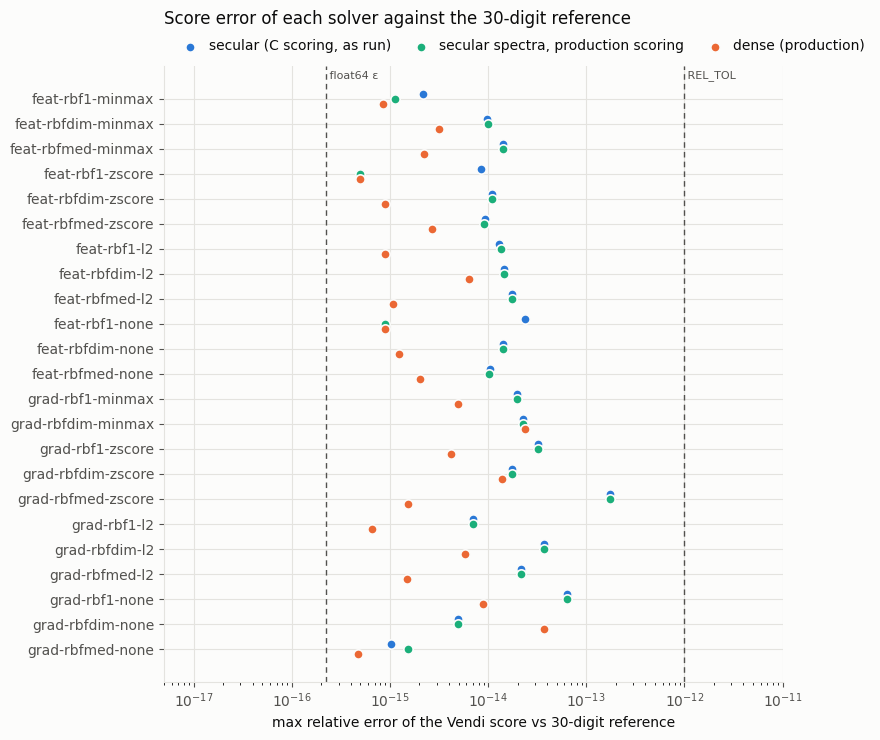

In [9]:
INK, INK_2, SURFACE, GRID_C = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # categorical slots 1-3 of the dataviz reference palette
FLOOR = 1e-17  # where exactly-zero errors would be drawn on the log axis


def style(ax):
    ax.set_facecolor(SURFACE)
    ax.figure.set_facecolor(SURFACE)
    ax.grid(color=GRID_C, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID_C)
    ax.tick_params(colors=INK_2, labelcolor=INK_2)


a = acc.set_index("setting").loc[acc.setting[::-1]]
y = np.arange(len(a))
fig, ax = plt.subplots(figsize=(8.5, 7.5))
style(ax)
for col, color, label, dy in (("max_rel_err_score_S", BLUE, "secular (C scoring, as run)", 0.2),
                              ("max_rel_err_score_S_rescored", AQUA, "secular spectra, production scoring", 0.0),
                              ("max_rel_err_score_E", ORANGE, "dense (production)", -0.2)):
    ax.scatter(a[col].clip(lower=FLOOR), y + dy, s=45, color=color, label=label,
               edgecolor=SURFACE, linewidth=1.2, zorder=3)
for xv, text in ((np.finfo(float).eps, "float64 ε"), (REL_TOL, "REL_TOL")):
    ax.axvline(xv, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    ax.text(xv, len(a) - 0.3, f" {text}", color=INK_2, fontsize=8, va="bottom")
ax.set_xscale("log")
ax.set_xlim(FLOOR / 2, 1e-11)
ax.set_yticks(y, a.index)
ax.set_xlabel("max relative error of the Vendi score vs 30-digit reference", color=INK)
ax.set_title("Score error of each solver against the 30-digit reference", color=INK, loc="left", pad=30)
ax.legend(frameon=False, labelcolor=INK, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3,
          handletextpad=0.3, columnspacing=1.2)
plt.tight_layout()

## 5. Agreement over the whole pool

The reference covers a few candidates per setting. Across all 12,388 pool candidates, the secular and
dense solvers are compared directly, and the secular spectra are checked against the exact-spectrum
identities, which hold for the exact spectrum of K_aug(u) whatever solver computed it: it sums to the
trace, its squares sum to ‖K_aug(u)‖²_F, and it interlaces with eig(K_LL). A root-finder bug (a missed
root, a bracket-midpoint fallback, a NaN) breaks them. Each violation is converted into the smallest
per-eigenvalue error that could cause it and reported in units of τ. `expected_float64_err` is the relative score error any backward-stable float64 eigensolver
should be expected to make for the worst candidate (condition number × ε). It is larger for
all-ones-like kernels, whose near-zero eigenvalues make the entropy sensitive to rounding.

In [10]:
def identity_violations(K_LL, K_UL, spec):
    # Per-eigenvalue error implied by each identity's violation (max over candidates), absolute units.
    lam_L = np.linalg.eigvalsh(K_LL)
    n = spec.shape[1]
    tr = np.trace(K_LL) + 1.0
    fro2 = (K_LL ** 2).sum() + 2.0 * (K_UL ** 2).sum(1) + 1.0
    trace = np.abs(spec.sum(1) - tr) / n                                   # |sum dlam| <= n max|dlam|
    frob = np.abs((spec ** 2).sum(1) - fro2) / (2.0 * np.abs(spec).sum(1))  # |sum 2 lam dlam| <= 2 sum|lam| max|dlam|
    interlace = np.maximum(np.maximum(spec[:, :-1] - lam_L, 0).max(1),     # lam'_i <= lam_i <= lam'_{i+1}
                           np.maximum(lam_L - spec[:, 1:], 0).max(1))
    return trace.max(), frob.max(), interlace.max()


def pool_summary(row):
    s = row.setting
    r = RES[s]
    E, S = r["E"], r["S"]
    vcfg = vendi_cfg(row.emb, row.norm, row.gamma)
    K_LL, K_UL, _ = kernels(vcfg, *normalized(vcfg, row.key))
    K_LL, K_UL = K_LL.cpu().numpy(), K_UL.cpu().numpy()
    _, spec = secular_scores(K_LL, K_UL, want_eigs=True)  # the spectra behind r["S"] (deterministic)
    tau = deflation_tol(K_LL)
    trace, frob, interlace = identity_violations(K_LL, K_UL, spec)
    return dict(
        setting=s,
        frac_near_one=float(r["kernel_frac_near_one"]), frac_near_zero=float(r["kernel_frac_near_zero"]),
        score_range=f"[{E.min():.4f}, {E.max():.4f}]",
        max_rel_S_minus_E=(np.abs(S - E) / E).max(),
        max_rel_Srescored_minus_E=(np.abs(r["S_rescored"] - E) / E).max(),
        expected_float64_err=r["cond"].max() * np.finfo(float).eps,  # cond * eps, see score_setting
        max_eig_diff_S_vs_E_in_tau=r["eig_diff"].max() / tau,
        trace_in_tau=trace / tau, frob_in_tau=frob / tau, interlace_in_tau=interlace / tau,
        K_LL_asym=float(r["K_LL_asym"]),
    )


pool = pd.DataFrame([pool_summary(r) for r in scored.itertuples()])
with pd.option_context("display.float_format", "{:.2e}".format, "display.width", 250):
    display(pool.set_index("setting"))

,frac_near_one,frac_near_zero,score_range,max_rel_S_minus_E,max_rel_Srescored_minus_E,expected_float64_err,max_eig_diff_S_vs_E_in_tau,trace_in_tau,frob_in_tau,interlace_in_tau,K_LL_asym
setting,,,,,,,,,,,
feat-rbf1-minmax,0.00e+00,9.46e-01,"[240.8934, 241.7010]",9.76e-15,2.70e-15,3.35e-15,6.61e-02,1.09e-02,1.16e-02,3.07e-02,0.00e+00
feat-rbfdim-minmax,1.43e-01,0.00e+00,"[1.3831, 1.3851]",2.17e-14,2.17e-14,6.12e-13,9.32e-04,8.76e-04,1.98e-01,1.96e-04,0.00e+00
feat-rbfmed-minmax,4.82e-04,0.00e+00,"[4.7962, 4.8278]",2.12e-14,2.12e-14,3.24e-13,1.27e-03,9.84e-04,1.30e-01,1.36e-04,0.00e+00
feat-rbf1-zscore,0.00e+00,1.00e+00,"[251.0000, 251.0000]",8.95e-15,9.06e-16,1.01e-15,6.69e-01,2.24e-02,2.75e-02,5.99e-02,0.00e+00
feat-rbfdim-zscore,0.00e+00,3.35e-01,"[28.6414, 29.1361]",1.55e-14,1.51e-14,8.48e-14,3.54e-03,2.23e-03,6.69e-02,0.00e+00,0.00e+00
feat-rbfmed-zscore,4.82e-04,0.00e+00,"[5.0630, 5.1067]",2.17e-14,2.18e-14,3.17e-13,1.54e-03,1.19e-03,1.49e-01,1.76e-04,0.00e+00
feat-rbf1-l2,9.64e-05,0.00e+00,"[12.2910, 12.4415]",2.31e-14,2.26e-14,1.56e-13,2.28e-03,1.57e-03,8.59e-02,3.40e-05,0.00e+00
feat-rbfdim-l2,1.00e+00,0.00e+00,"[1.0116, 1.0117]",3.40e-14,3.40e-14,8.55e-13,6.38e-04,5.72e-04,1.41e-01,3.19e-04,0.00e+00
feat-rbfmed-l2,1.96e-03,0.00e+00,"[4.5904, 4.6199]",2.76e-14,2.76e-14,3.27e-13,1.41e-03,1.12e-03,1.45e-01,0.00e+00,0.00e+00


## 6. Where the batches differ, the cutoff is tied

Each solver's batch is the top 250 by `np.argsort(scores)[::-1]`, as in `_get_vendi`. The analysis
compares four batches: the two reproduced here and the two the runs stored (`request_pool[0]` in
`stored.npz`). A candidate counts as **tied at the cutoff** when its score equals the cutoff score to
`REL_TOL` under both solvers. The claim is that every candidate in one batch but not the other is
tied.

In [11]:
def top_b(scores):
    return set(np.argsort(scores)[::-1][:B].tolist())


def batch_analysis(row):
    r = RES[row.setting]
    E, S = r["E"], r["S"]
    sE, sS = np.sort(E)[::-1], np.sort(S)[::-1]
    bE, bS = sE[B - 1], sS[B - 1]  # cutoff scores
    tied = (np.abs(E - bE) <= REL_TOL * bE) & (np.abs(S - bS) <= REL_TOL * bS)
    batches = {"E": top_b(E), "S": top_b(S)}
    for name, rd in (("E_run", row.rd_exact), ("S_run", row.rd_secular)):
        batches[name] = set(np.load(rd / "stored.npz")["request_pool"][0].tolist()) if isinstance(rd, Path) else None
    in_E = np.zeros(len(E), bool)
    in_E[list(batches["E"])] = True

    def compare(a, b):
        if batches[a] is None or batches[b] is None:
            return np.nan, np.nan
        diff = np.fromiter(batches[a] ^ batches[b], int)
        return len(batches[a] & batches[b]), bool(tied[diff].all()) if len(diff) else True

    rel_gap = (bE - sE[B]) / bE
    clean = bool(rel_gap > REL_TOL)
    out = dict(setting=row.setting, rel_gap_at_cutoff=rel_gap, clean_cutoff=clean,
               n_tied_at_cutoff=int(tied.sum()),
               # batch slots filled from a tie group that also has members outside the batch
               picks_by_tiebreak=0 if clean else int((tied & in_E).sum()))
    for a, b in (("E_run", "S_run"), ("E", "S"), ("E", "E_run"), ("S", "S_run")):
        out[f"overlap_{a}_vs_{b}"], out[f"diff_all_tied_{a}_vs_{b}"] = compare(a, b)
    return out


batch = pd.DataFrame([batch_analysis(r) for r in scored.itertuples()])
with pd.option_context("display.float_format", "{:.2e}".format, "display.width", 250):
    display(batch.set_index("setting")[["rel_gap_at_cutoff", "n_tied_at_cutoff", "picks_by_tiebreak",
                                        "overlap_E_run_vs_S_run", "diff_all_tied_E_run_vs_S_run",
                                        "overlap_E_vs_S", "diff_all_tied_E_vs_S",
                                        "overlap_E_vs_E_run", "overlap_S_vs_S_run"]])

,rel_gap_at_cutoff,n_tied_at_cutoff,picks_by_tiebreak,overlap_E_run_vs_S_run,diff_all_tied_E_run_vs_S_run,overlap_E_vs_S,diff_all_tied_E_vs_S,overlap_E_vs_E_run,overlap_S_vs_S_run
setting,,,,,,,,,
feat-rbf1-minmax,0.00e+00,1252,250,232,True,232,True,250,250
feat-rbfdim-minmax,2.76e-07,1,0,250,True,250,True,250,250
feat-rbfmed-minmax,9.97e-08,1,0,250,True,250,True,250,250
feat-rbf1-zscore,0.00e+00,12388,250,1,True,1,True,250,250
feat-rbfdim-zscore,3.17e-07,1,0,250,True,250,True,250,250
feat-rbfmed-zscore,8.37e-07,1,0,250,True,250,True,250,250
feat-rbf1-l2,4.09e-06,1,0,250,True,250,True,250,250
feat-rbfdim-l2,2.77e-09,1,0,250,True,250,True,250,250
feat-rbfmed-l2,1.33e-07,1,0,250,True,250,True,250,250


Columns:

- `overlap_E_run_vs_S_run`: what the sweep showed, i.e. the overlap of the batches stored by the exact
  and the secular run.
- `diff_all_tied_*`: whether every candidate in one batch but not the other is tied at the cutoff.
- `picks_by_tiebreak`: how many of the 250 slots were filled from a tie group that has members left
  outside the batch.
- `overlap_S_vs_S_run` / `overlap_E_vs_E_run`: whether this notebook reproduces each run's own batch.

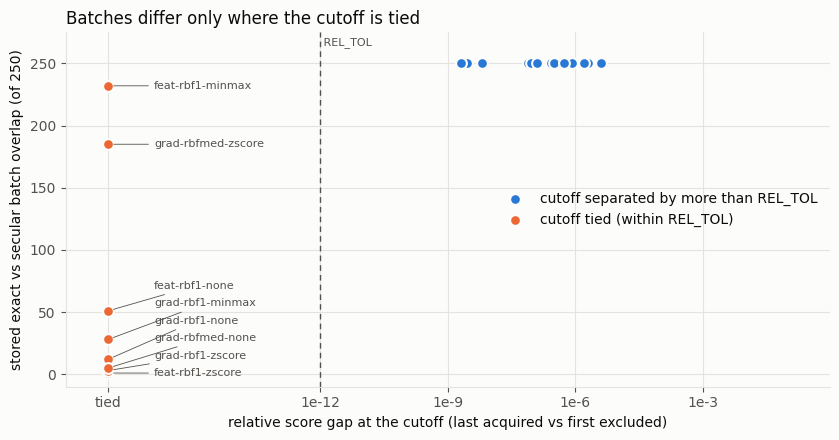

In [12]:
b = batch.dropna(subset=["overlap_E_run_vs_S_run"])
floor = 1e-17  # where settings with a tied cutoff are drawn
clean = b.clean_cutoff.values.astype(bool)
x = np.where(clean, b.rel_gap_at_cutoff.clip(lower=floor), floor)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
style(ax)
for mask, color, label in ((clean, BLUE, "cutoff separated by more than REL_TOL"),
                           (~clean, ORANGE, "cutoff tied (within REL_TOL)")):
    ax.scatter(x[mask], b.overlap_E_run_vs_S_run.values[mask], s=60, color=color, label=label,
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
# label the tied settings, stacking labels that would collide and tying them to their dot
label_y = None
for yi, name in sorted(zip(b.overlap_E_run_vs_S_run.values[~clean], b.setting.values[~clean])):
    label_y = yi if label_y is None else max(yi, label_y + 14)
    ax.annotate(name, (floor, yi), xytext=(floor * 12, label_y), textcoords="data", va="center",
                fontsize=8, color=INK_2,
                arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.6, shrinkA=2, shrinkB=4))
ax.axvline(REL_TOL, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(REL_TOL, 262, " REL_TOL", color=INK_2, fontsize=8, va="bottom")
ax.set_xscale("log")
ax.set_xlim(floor / 10, 1)
ticks = [floor, 1e-12, 1e-9, 1e-6, 1e-3]
ax.set_xticks(ticks, ["tied"] + [f"1e{int(np.log10(t))}" for t in ticks[1:]])
ax.set_ylim(-10, 275)
ax.set_xlabel("relative score gap at the cutoff (last acquired vs first excluded)", color=INK)
ax.set_ylabel(f"stored exact vs secular batch overlap (of {B})", color=INK)
ax.set_title("Batches differ only where the cutoff is tied", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK, loc="center right")
plt.tight_layout()

### A tied cutoff up close

The candidates ranked 245–254 by the secular solver, for one tied and one clean setting. In the tied
setting the scores are identical far beyond `REL_TOL`, so the tie-break decides which of them fill the
last slots.

In [13]:
def around_cutoff(name, width=5):
    r = RES[name]
    order_S = np.argsort(r["S"])[::-1]
    in_E, in_S = top_b(r["E"]), top_b(r["S"])
    ranks = range(B - width, B + width)
    return pd.DataFrame(dict(
        rank_by_secular=[k + 1 for k in ranks],
        candidate=[order_S[k] for k in ranks],
        secular_score=[f"{r['S'][order_S[k]]:.15f}" for k in ranks],
        dense_score=[f"{r['E'][order_S[k]]:.15f}" for k in ranks],
        in_secular_batch=[order_S[k] in in_S for k in ranks],
        in_dense_batch=[order_S[k] in in_E for k in ranks],
    )).set_index("rank_by_secular")


for name in ("grad-rbf1-none", "feat-rbfmed-l2"):
    print(name)
    display(around_cutoff(name))

grad-rbf1-none


,candidate,secular_score,dense_score,in_secular_batch,in_dense_batch
rank_by_secular,,,,,
246,239,1.032846853684417,1.032846853684440,True,False
247,9250,1.032846853684417,1.032846853684443,True,False
248,9343,1.032846853684417,1.032846853684442,True,False
249,9248,1.032846853684417,1.032846853684438,True,False
250,9286,1.032846853684417,1.032846853684445,True,True
251,3220,1.032846853684417,1.032846853684440,False,False
252,9336,1.032846853684417,1.032846853684442,False,False
253,9289,1.032846853684417,1.032846853684442,False,False
254,9320,1.032846853684417,1.032846853684443,False,False


feat-rbfmed-l2


,candidate,secular_score,dense_score,in_secular_batch,in_dense_batch
rank_by_secular,,,,,
246,7873,4.612454667368494,4.612454667368544,True,True
247,7347,4.612448840974525,4.612448840974610,True,True
248,646,4.612447529281135,4.612447529281141,True,True
249,11649,4.612440327091105,4.612440327091113,True,True
250,7589,4.612439580588304,4.612439580588382,True,True
251,7408,4.612438967468387,4.612438967468401,False,False
252,8072,4.612436634769650,4.612436634769672,False,False
253,12141,4.612421181433035,4.612421181433101,False,False
254,9371,4.612418435611883,4.612418435611963,False,False


## 7. Verdict

In [14]:
has_runs = batch.overlap_E_run_vs_S_run.notna()
tied_true = (acc.true_rel_gap_at_E_cutoff.abs() <= REL_TOL).values
checks = {
    "helpers are bitwise the production dense / secular functions":
        all(all(v) for v in BITWISE.values()),
    "rebuilt kernels reproduce the runs' logged diagnostics (rel err < 1e-9)":
        bool((scored.diag_rel_err.dropna() < 1e-9).all()),
    "secular eigenvalues match the 30-digit reference to EIG_TOL x tau":
        bool((acc.max_err_eig_S_in_tau <= EIG_TOL).all()),
    "secular scores match the 30-digit reference to REL_TOL":
        bool((acc.max_rel_err_score_S <= REL_TOL).all()),
    "dense scores match the 30-digit reference to REL_TOL":
        bool((acc.max_rel_err_score_E <= REL_TOL).all()),
    "secular and dense scores agree to REL_TOL on every pool candidate":
        bool((pool.max_rel_S_minus_E <= REL_TOL).all()),
    "secular spectra satisfy trace / Frobenius / interlacing identities to EIG_TOL x tau":
        bool((pool[["trace_in_tau", "frob_in_tau", "interlace_in_tau"]] <= EIG_TOL).all().all()),
    "reproduced secular batch == stored secular run batch":
        bool((batch.overlap_S_vs_S_run.dropna() == B).all()),
    "every stored exact-vs-secular batch difference is tied at the cutoff":
        bool(batch.loc[has_runs, "diff_all_tied_E_run_vs_S_run"].astype(bool).all()),
    "every reproduced exact-vs-secular batch difference is tied at the cutoff":
        bool(batch.diff_all_tied_E_vs_S.astype(bool).all()),
    "settings with a clean cutoff acquire identical batches (stored runs)":
        bool((batch.loc[has_runs & batch.clean_cutoff, "overlap_E_run_vs_S_run"] == B).all()),
    "the exact (30-digit) cutoff gap is below REL_TOL exactly in the tied settings":
        bool((tied_true == ~batch.clean_cutoff.values.astype(bool)).all()),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
print(f"\n{len(NONFINITE)} setting(s) excluded for a non-finite kernel: {[d['setting'] for d in NONFINITE]}")
print(f"reproduced dense batch == stored exact run batch in "
      f"{int((batch.overlap_E_vs_E_run == B).sum())}/{int(batch.overlap_E_vs_E_run.notna().sum())} settings "
      "(informational: in tied settings the dense tie order also depends on GPU rounding)")
assert all(checks.values()), 'some checks failed - see above'

PASS  helpers are bitwise the production dense / secular functions
PASS  rebuilt kernels reproduce the runs' logged diagnostics (rel err < 1e-9)
PASS  secular eigenvalues match the 30-digit reference to EIG_TOL x tau
PASS  secular scores match the 30-digit reference to REL_TOL
PASS  dense scores match the 30-digit reference to REL_TOL
PASS  secular and dense scores agree to REL_TOL on every pool candidate
PASS  secular spectra satisfy trace / Frobenius / interlacing identities to EIG_TOL x tau
PASS  reproduced secular batch == stored secular run batch
PASS  every stored exact-vs-secular batch difference is tied at the cutoff
PASS  every reproduced exact-vs-secular batch difference is tied at the cutoff
PASS  settings with a clean cutoff acquire identical batches (stored runs)
PASS  the exact (30-digit) cutoff gap is below REL_TOL exactly in the tied settings

1 setting(s) excluded for a non-finite kernel: ['grad-rbfmed-minmax']
reproduced dense batch == stored exact run batch in 23/23 